# Selecting the difference order for out-of-sample stability

The augmented Dickey Fuller calculation tests whether the transformed series still behaves as if it has a unit root:

$$
\Delta Y_t=\alpha_0+\rho Y_{t-1}+\gamma\Delta Y_{t-1}+\varepsilon_t,
\qquad H_0:\rho=0.
$$

Here, $Y_t$ is the transformed value; $\Delta Y_t=Y_t-Y_{t-1}$; $\alpha_0$ is a constant; $\rho$ is the level coefficient. $\gamma$ is the coefficient on one lagged change; $\varepsilon_t$ is the remaining error; $H_0$ is the unit-root null statement.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("08_fractional_differentiation");
using CSV, Printf, HypothesisTests
using RiskLabAI.Data: calculate_weights_std,calculate_weights_ffd,fractional_difference_std,fractional_difference_fixed,adaptive_fractional_difference
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
violet = "#C084FC"

function natural_weights(degree,size)
    values = ones(size)
    for lag in 1:size-1
        values[lag+1] = -values[lag]*(degree-lag+1)/lag
    end
    return values
end

function adf_record(values)
    test = ADFTest(Float64.(values),:constant,1)
    return (statistic=test.stat,p_value=pvalue(test),lag=test.lag,observations=test.n,critical=HypothesisTests.adf_cv(test.n,:constant)[2])
end

function fixed_transform(values,degree,cutoff)
    transformed = fractional_difference_fixed(values,degree;threshold=cutoff)
    positions = findall(isfinite,transformed)
    return (positions=positions,values=transformed[positions])
end

function save_adf_records(records,stem)
    save_data(DataFrame(records),paths,stem)
    return nothing
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end


box_summary! (generic function with 1 method)

## Training Rule

Among the tested orders, the training rule chooses the smallest one whose unit-root p-value is below the chosen level:

$$
\widehat d=\min\{d\in\mathcal D:p_{\mathrm{train}}(d)<\alpha\},
\qquad \mathcal D=\{0,0.1,\ldots,1\},\qquad \alpha=0.05.
$$

Here, $\widehat d$ is the selected order; $\mathcal D$ is the fixed set of candidate orders; $p_{\mathrm{train}}(d)$ is the training p-value. $\alpha=0.05$ is the decision level; $\min$ selects the smallest passing candidate.

In [2]:
degrees = round.(collect(range(0.,1.;length=11));digits=1)
threshold,significance = 1e-3,.05
split_position = floor(Int,.70length(log_price))
train = log_price[1:split_position]
test_positions = split_position+1:length(log_price)

function evaluate(values,degree,cutoff)
    transformed = fixed_transform(values,degree,cutoff)
    record = merge(adf_record(transformed.values),(order=degree,cutoff=cutoff,width=length(calculate_weights_ffd(degree,cutoff)),usable=length(transformed.values),correlation=cor(values[transformed.positions],transformed.values)))
    return record,transformed
end

function selection_table(rows,observation_name)
    table = DataFrame(rows)
    table = table[:,[:order,:width,:usable,:statistic,:p_value,:critical,:correlation]]
    rename!(table,["Order","Retained weights",observation_name,"ADF statistic","p-value","Five percent critical value","Correlation with log price"])
    return table
end

train_rows,test_rows,full_rows,sensitivity_rows,candidate_rows_all,transform_values = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
train_series,full_series = Dict{Float64,Any}(),Dict{Float64,Any}()
for degree in degrees
    record,transformed = evaluate(train,degree,threshold)
    push!(train_rows,record)
    train_series[degree] = transformed
    for (position,value) in zip(transformed.positions,transformed.values)
        push!(transform_values,(sample="Training",order=degree,position=position,time=close_index[position],value=value))
    end
end
train_order_selection = selection_table(train_rows,"Usable observations")
selected_degree = minimum(train_order_selection[train_order_selection[!,"p-value"].<significance,"Order"])
for degree in degrees
    record,transformed = evaluate(log_price,degree,threshold)
    push!(full_rows,record)
    retained = transformed.positions.>split_position
    held_out,positions = transformed.values[retained],transformed.positions[retained]
    test_record = merge(adf_record(held_out),(order=degree,width=record.width,usable=length(held_out),correlation=cor(log_price[positions],held_out)))
    push!(test_rows,test_record)
    full_series[degree] = transformed
    for (position,value) in zip(transformed.positions,transformed.values)
        push!(transform_values,(sample="Full",order=degree,position=position,time=close_index[position],value=value))
    end
end
test_order_evaluation = selection_table(test_rows,"Held-out observations")
for cutoff in [1e-2,1e-3,1e-4,1e-5]
    candidates = NamedTuple[]
    for degree in degrees
        transformed = fixed_transform(train,degree,cutoff)
        length(transformed.values)<20 && continue
        record,_ = evaluate(train,degree,cutoff)
        push!(candidates,record)
        push!(candidate_rows_all,record)
    end
    chosen = first(filter(record->record.p_value<significance,candidates))
    full = fixed_transform(log_price,chosen.order,cutoff)
    retained = full.positions.>split_position
    held_out,positions = full.values[retained],full.positions[retained]
    push!(sensitivity_rows,(cutoff=cutoff,order=chosen.order,width=chosen.width,training=chosen.usable,training_p=chosen.p_value,training_correlation=chosen.correlation,held_out=length(held_out),held_out_p=adf_record(held_out).p_value,held_out_correlation=cor(log_price[positions],held_out)))
end
threshold_sensitivity = DataFrame(sensitivity_rows)
rename!(threshold_sensitivity,["Cutoff","Selected order","Retained weights","Training observations","Training p-value","Training correlation","Held-out observations","Held-out p-value","Held-out correlation"])
save_table(train_order_selection,paths,"train_order_selection";caption="Training results for candidate fractional orders.",label="tab:chapter7-train-selection")
save_table(test_order_evaluation,paths,"test_order_evaluation";caption="Held-out results using fixed weights and earlier history.",label="tab:chapter7-test-evaluation")
save_table(threshold_sensitivity,paths,"threshold_sensitivity";caption="Sensitivity of order selection to the weight cutoff.",label="tab:chapter7-threshold-sensitivity")
save_adf_records(train_rows,"training_adf_records")
save_adf_records(test_rows,"held_out_adf_records")
save_adf_records(full_rows,"full_adf_records")
save_adf_records(candidate_rows_all,"cutoff_candidate_records")
save_data(DataFrame(transform_values),paths,"chronological_transform_values");


Row,Order,Retained weights,Usable observations,ADF statistic,p-value,Five percent critical value,Correlation with log price
,Float64,Int64,Int64,Float64,Float64,Float64,Float64
1,0.0,1,2083,-2.51096,0.112831,-2.86293,1.0
2,0.1,62,2022,-3.45551,0.00920595,-2.86297,0.994709
3,0.2,73,2011,-5.07977,1.53932e-5,-2.86298,0.965977
4,0.3,66,2018,-7.3023,1.32882e-10,-2.86297,0.90721
5,0.4,55,2029,-10.3208,3.01211e-18,-2.86297,0.814786
6,0.5,44,2040,-14.0775,2.86704e-26,-2.86296,0.689854
7,0.6,34,2050,-18.2805,2.30889e-30,-2.86295,0.547926
8,0.7,26,2058,-22.6623,0.0,-2.86295,0.405447
9,0.8,18,2066,-26.8473,0.0,-2.86294,0.288527


Row,Order,Retained weights,Held-out observations,ADF statistic,p-value,Five percent critical value,Correlation with log price
,Float64,Int64,Int64,Float64,Float64,Float64,Float64
1,0.0,1,893,-2.49352,0.117059,-2.86479,1.0
2,0.1,62,893,-3.41162,0.010569,-2.86479,0.986658
3,0.2,73,893,-4.69334,8.66112e-5,-2.86479,0.932941
4,0.3,66,893,-6.28465,3.72362e-8,-2.86479,0.84283
5,0.4,55,893,-8.16113,9.13774e-13,-2.86479,0.725315
6,0.5,44,893,-10.2354,4.9044e-18,-2.86479,0.593907
7,0.6,34,893,-12.4057,4.45734e-23,-2.86479,0.464685
8,0.7,26,893,-14.6069,4.0809e-27,-2.86479,0.347155
9,0.8,18,893,-16.761,1.31014e-29,-2.86479,0.253563


Row,Cutoff,Selected order,Retained weights,Training observations,Training p-value,Training correlation,Held-out observations,Held-out p-value,Held-out correlation
,Float64,Float64,Int64,Int64,Float64,Float64,Int64,Float64,Float64
1,0.01,0.2,11,2073,0.00610131,0.995545,893,0.00212483,0.985179
2,0.001,0.1,62,2022,0.00920595,0.994709,893,0.010569,0.986658
3,0.0001,0.1,503,1581,0.020725,0.981137,893,0.0108363,0.980966
4,1.0e-5,0.4,1458,626,4.49246e-9,0.741655,893,4.54661e-12,0.705437


## Held-Out Evaluation

After the order is chosen on training data, each held-out value uses only its present and past levels with the already fixed weights:

$$
\widetilde X_t^{(\widehat d,\tau)}
=\sum_{k=0}^{m_{\tau}(\widehat d)-1}\omega_kX_{t-k},
\qquad t\in\mathcal T_{\mathrm{test}}.
$$

Here, $\widehat d$ is the training-selected order; $\tau$ is the fixed cutoff; $m_{\tau}(\widehat d)$ is the retained weight count. $\omega_k$ is the weight at lag $k$; $X_{t-k}$ is an observed present or past level; $\mathcal T_{\mathrm{test}}$ is the held-out time set.

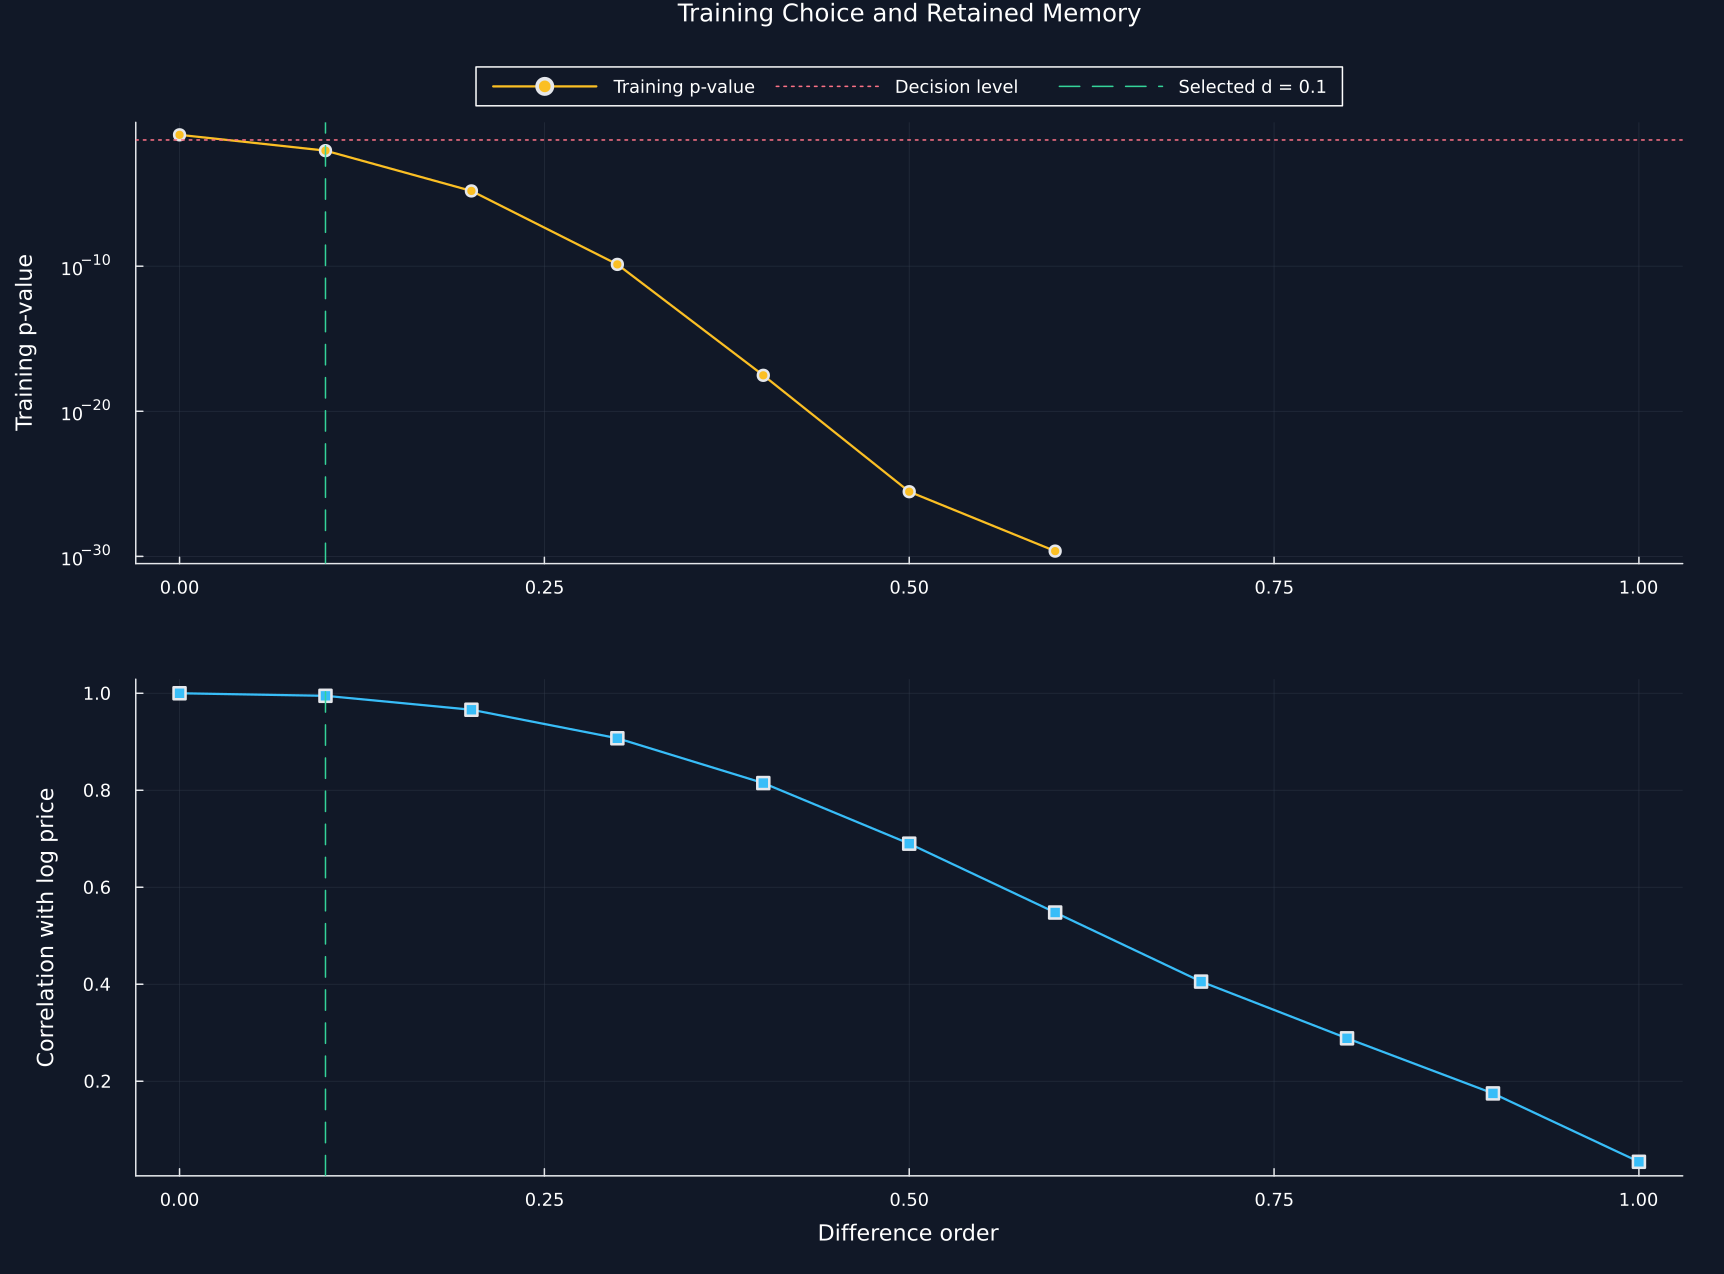

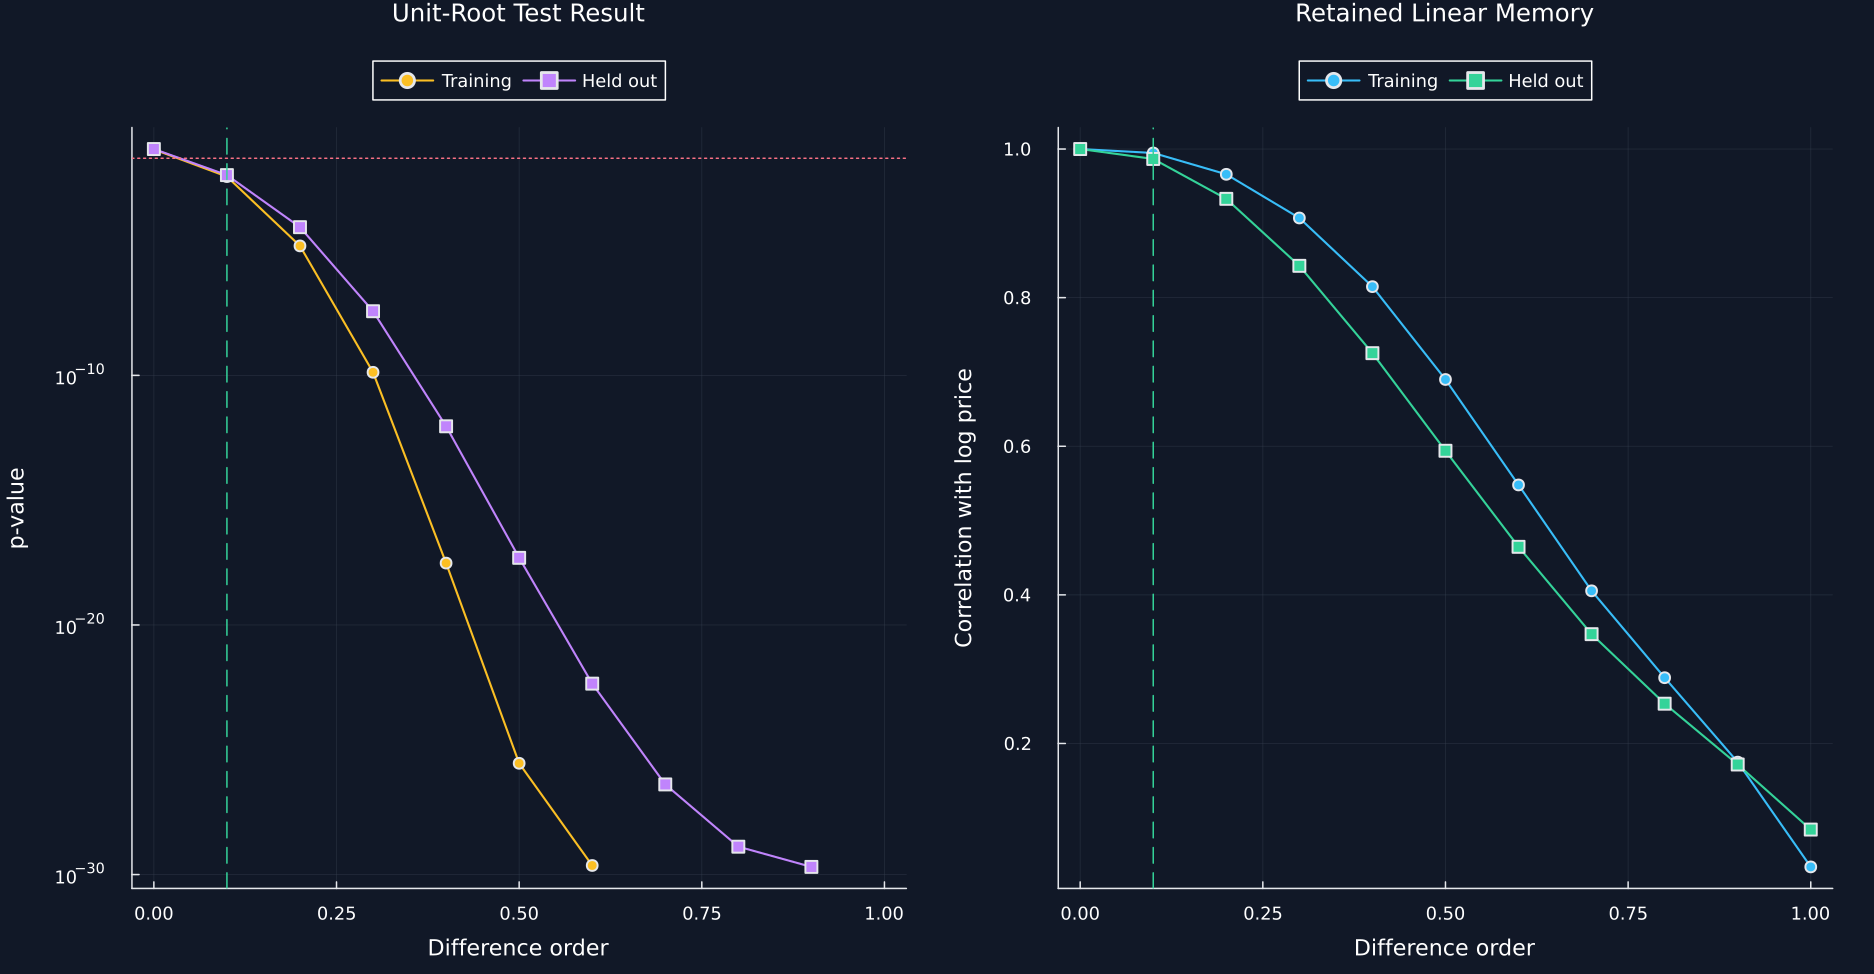

In [3]:
train_selected = only(eachrow(train_order_selection[train_order_selection.Order.==selected_degree,:]))
test_selected = only(eachrow(test_order_evaluation[test_order_evaluation.Order.==selected_degree,:]))
plot_pvalues(values) = [value>0 ? value : NaN for value in values]
p1 = plot(degrees,plot_pvalues(train_order_selection[!,"p-value"]);color=palette.amber,marker=:circle,linewidth=1.5,label="Training p-value",yscale=:log10,ylabel="Training p-value",title="Training Choice and Retained Memory",legend=:outertop,legend_column=3)
hline!(p1,[significance];color=palette.rose,linewidth=1.,linestyle=:dot,label="Decision level")
vline!(p1,[selected_degree];color=palette.green,linewidth=1.,linestyle=:dash,label="Selected d = $selected_degree")
p2 = plot(degrees,train_order_selection[!,"Correlation with log price"];color=palette.cyan,marker=:square,linewidth=1.5,label="Training correlation",xlabel="Difference order",ylabel="Correlation with log price",legend=false)
vline!(p2,[selected_degree];color=palette.green,linewidth=1.,linestyle=:dash,label=false)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"train_order_selection")
p1 = plot(degrees,plot_pvalues(train_order_selection[!,"p-value"]);color=palette.amber,marker=:circle,linewidth=1.4,label="Training",yscale=:log10,title="Unit-Root Test Result",xlabel="Difference order",ylabel="p-value",legend=:outertop,legend_column=2)
plot!(p1,degrees,plot_pvalues(test_order_evaluation[!,"p-value"]);color=violet,marker=:square,linewidth=1.4,label="Held out")
hline!(p1,[significance];color=palette.rose,linewidth=1.,linestyle=:dot,label=false)
vline!(p1,[selected_degree];color=palette.green,linewidth=1.,linestyle=:dash,label=false)
p2 = plot(degrees,train_order_selection[!,"Correlation with log price"];color=palette.cyan,marker=:circle,linewidth=1.4,label="Training",title="Retained Linear Memory",xlabel="Difference order",ylabel="Correlation with log price",legend=:outertop,legend_column=2)
plot!(p2,degrees,test_order_evaluation[!,"Correlation with log price"];color=palette.green,marker=:square,linewidth=1.4,label="Held out")
vline!(p2,[selected_degree];color=palette.green,linewidth=1.,linestyle=:dash,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"out_of_sample_stability")


## Threshold Sensitivity

Repeating the training rule at several cutoffs shows whether the chosen order depends strongly on how much of the weight tail is retained:

$$
\widehat d(\tau)=\min\{d\in\mathcal D:p_{\mathrm{train}}(d,\tau)<0.05\},
\qquad
\tau\in\{10^{-2},10^{-3},10^{-4},10^{-5}\}.
$$

Here, $\widehat d(\tau)$ is the order chosen at cutoff $\tau$; $\mathcal D$ is the candidate set; $p_{\mathrm{train}}(d,\tau)$ is the training p-value. $10^{-2},10^{-3},10^{-4},10^{-5}$ are the four absolute-weight cutoffs; $0.05$ is the decision level.

## Known-Truth Long-Memory Test

A simulated change series has a known memory order, and cumulative summation adds one unit to the order needed for the price level:

$$
x_t=(1-B)^{-d_0}\varepsilon_t,
\qquad
P_t=\sum_{s=1}^{t}x_s,
\qquad
\tau_0=1+d_0.
$$

Here, $x_t$ is the simulated change at time $t$; $B$ moves a value back one step; $d_0$ is the chosen memory order. $\varepsilon_t$ is independent standard normal noise; $P_t$ is the cumulative level; $s$ indexes changes; $\tau_0$ is the true order for the level.

Row,Seed,True order,Minimum ADF order,Adaptive order,Minimum ADF absolute error,Adaptive absolute error
,Int64,Float64,Float64,Float64,Float64,Float64
1,100,1.45,0.6,0.768797,0.85,0.681203
2,101,1.45,0.75,0.957768,0.7,0.492232
3,102,1.45,0.7,0.901477,0.75,0.548523
4,103,1.45,0.75,0.756594,0.7,0.693406
5,104,1.45,0.7,0.952534,0.75,0.497466
6,105,1.45,0.7,0.974071,0.75,0.475929
7,106,1.45,0.75,0.799162,0.7,0.650838
8,107,1.45,0.8,0.819538,0.65,0.630462
9,108,1.45,0.8,0.853544,0.65,0.596456


Row,Method,Mean selected order,Mean absolute error,Median absolute error,Largest absolute error
,String,Float64,Float64,Float64,Float64
1,Minimum order passing the ADF test,0.64,0.81,0.75,1.45
2,Adaptive fractional difference,0.856248,0.593752,0.61397,0.693406


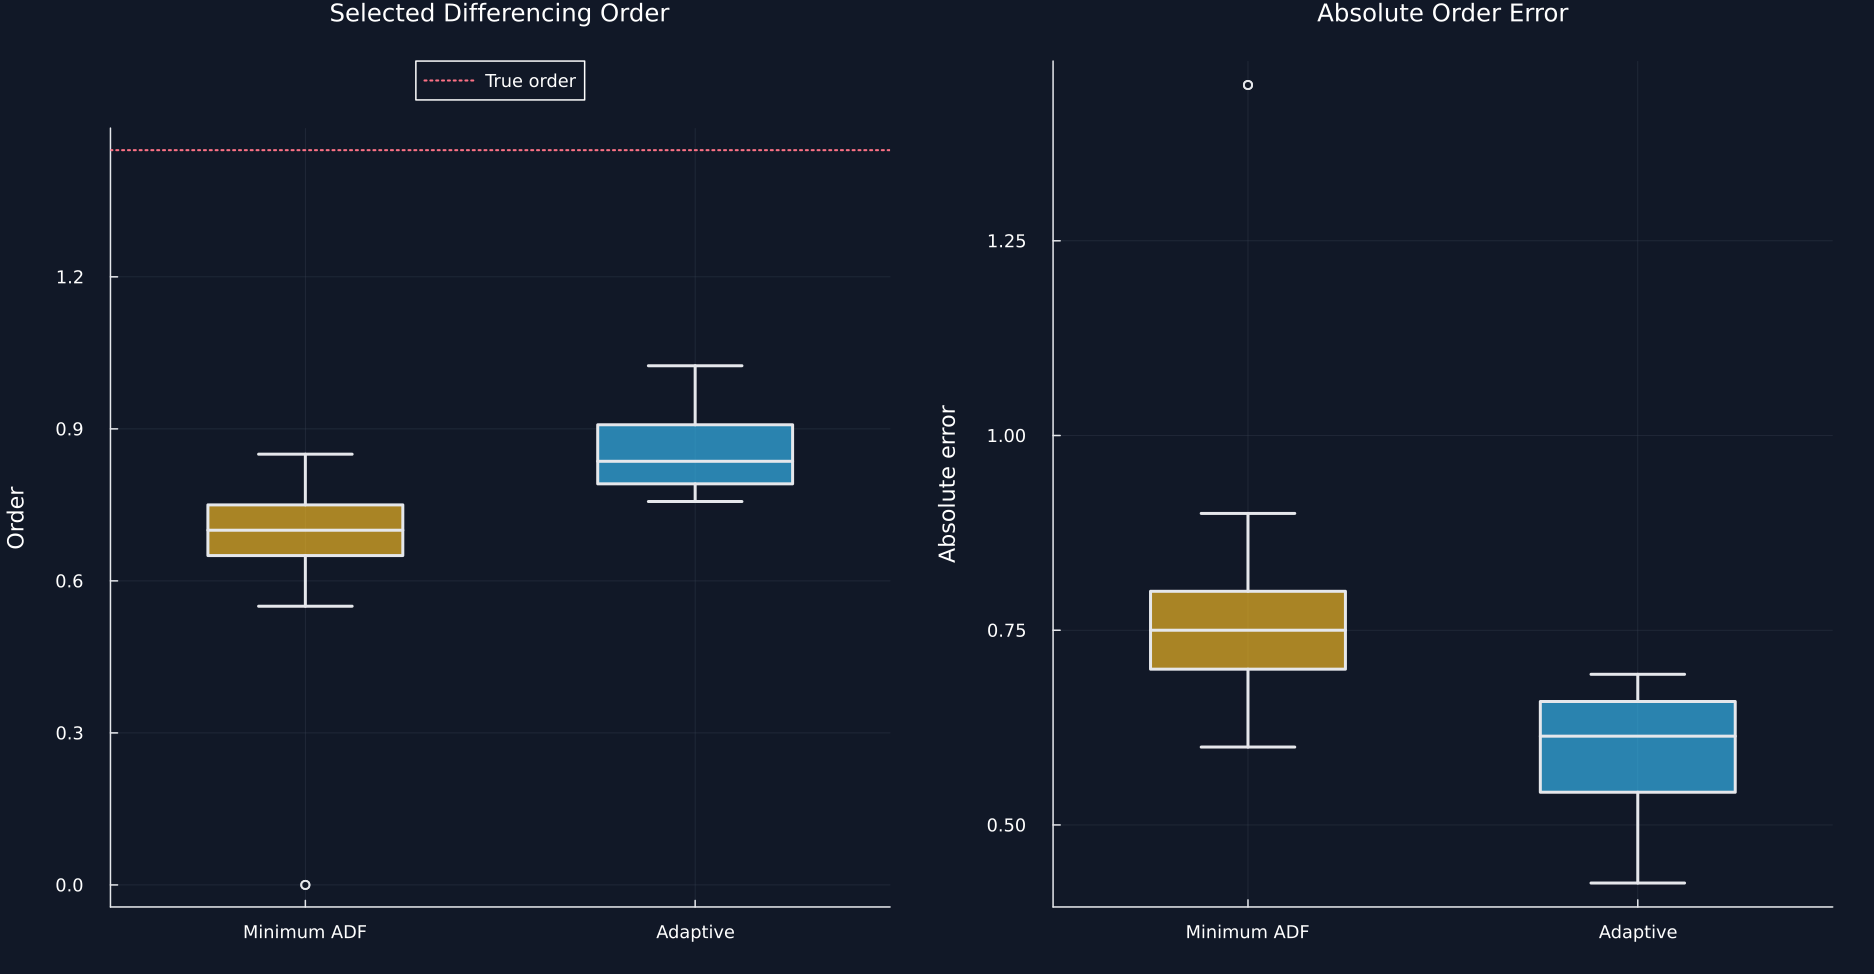

In [4]:
function arfima_increments(memory_order,count,random_generator;burn=512)
    total = count+burn
    innovations = randn(random_generator,total)
    coefficients = ones(total)
    for lag in 1:total-1
        coefficients[lag+1] = coefficients[lag]*(lag-1+memory_order)/lag
    end
    filtered = [sum(innovations[1:position].*reverse(coefficients[1:position])) for position in 1:total]
    return (increments=filtered[burn+1:end],innovations=innovations,coefficients=coefficients)
end

function minimum_stationary_order(price,order_grid;significance_level=.05,cutoff=1e-4)
    selected = last(order_grid)
    records = NamedTuple[]
    for order in order_grid
        transformed = fixed_transform(price,order,cutoff)
        length(transformed.values)<20 && continue
        selected = order
        record = adf_record(transformed.values)
        push!(records,merge((order=order,usable=length(transformed.values),),record))
        record.p_value<significance_level && return selected,records
    end
    return selected,records
end

true_memory_order,true_level_order = .45,1.45
simulation_length = 250
order_grid = round.(collect(0.:.05:1.2);digits=2)
order_rows,innovation_rows,simulation_rows,adaptive_rows,baseline_rows = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
for seed in 100:119
    random_generator = Xoshiro(seed)
    simulation = arfima_increments(true_memory_order,simulation_length,random_generator)
    simulated_price = cumsum(simulation.increments)
    adaptive_result = adaptive_fractional_difference(simulated_price;delta_grid=order_grid)
    baseline_order,baseline_records = minimum_stationary_order(simulated_price,order_grid)
    push!(order_rows,(seed=seed,true_order=true_level_order,baseline=baseline_order,adaptive=adaptive_result.order,baseline_error=abs(baseline_order-true_level_order),adaptive_error=abs(adaptive_result.order-true_level_order)))
    push!(adaptive_rows,(seed=seed,order=adaptive_result.order,d_hat=adaptive_result.d_hat,p_value=adaptive_result.adf_pvalue,memory_retained=adaptive_result.memory_retained,threshold=adaptive_result.threshold))
    for position in eachindex(simulation.innovations)
        push!(innovation_rows,(seed=seed,position=position,innovation=simulation.innovations[position],coefficient=simulation.coefficients[position]))
    end
    for position in eachindex(simulated_price)
        push!(simulation_rows,(seed=seed,position=position,increment=simulation.increments[position],price=simulated_price[position],adaptive=adaptive_result.series[position]))
    end
    for record in baseline_records
        push!(baseline_rows,merge((seed=seed,),record))
    end
end
order_recovery_runs = DataFrame(order_rows)
rename!(order_recovery_runs,["Seed","True order","Minimum ADF order","Adaptive order","Minimum ADF absolute error","Adaptive absolute error"])
summary_rows = NamedTuple[]
for (method,order_column,error_column) in [("Minimum order passing the ADF test","Minimum ADF order","Minimum ADF absolute error"),("Adaptive fractional difference","Adaptive order","Adaptive absolute error")]
    orders,errors = order_recovery_runs[!,order_column],order_recovery_runs[!,error_column]
    push!(summary_rows,(method=method,order=mean(orders),mean=mean(errors),median=median(errors),largest=maximum(errors)))
end
order_recovery_summary = DataFrame(summary_rows)
rename!(order_recovery_summary,["Method","Mean selected order","Mean absolute error","Median absolute error","Largest absolute error"])
save_table(order_recovery_runs,paths,"order_recovery_runs";caption="Known-truth differencing orders across twenty fixed seeds.",label="tab:chapter7-order-recovery-runs")
save_table(order_recovery_summary,paths,"order_recovery_summary";caption="Accuracy of two differencing-order rules on a known-truth long-memory process.",label="tab:chapter7-order-recovery-summary")
save_data(DataFrame(innovation_rows),paths,"arfima_innovations")
save_data(DataFrame(simulation_rows),paths,"arfima_simulations")
save_data(DataFrame(adaptive_rows),paths,"adaptive_decisions")
save_data(DataFrame(baseline_rows),paths,"minimum_order_adf_records")
function order_boxplot(groups,title,ylabel)
    figure = plot(;xticks=(1:2,["Minimum ADF","Adaptive"]),title,ylabel,xlims=(.5,2.5),legend=false)
    box_summary!(figure,groups,[palette.amber,palette.cyan])
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        outside = values[(values.<lower-1.5(upper-lower)).|(values.>upper+1.5(upper-lower))]
        scatter!(figure,fill(index,length(outside)),outside;markercolor=palette.background,markerstrokecolor=palette.text,markersize=3.,label=false)
    end
    return figure
end
p1 = order_boxplot([order_recovery_runs[!,"Minimum ADF order"],order_recovery_runs[!,"Adaptive order"]],"Selected Differencing Order","Order")
hline!(p1,[true_level_order];color=palette.rose,linestyle=:dot,linewidth=1.4,label="True order",legend=:outertop)
p2 = order_boxplot([order_recovery_runs[!,"Minimum ADF absolute error"],order_recovery_runs[!,"Adaptive absolute error"]],"Absolute Order Error","Absolute error")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"known_truth_order_recovery")


## Tests

In [5]:
selected_full,selected_train = full_series[selected_degree],train_series[selected_degree]
common_training_positions = intersect(selected_train.positions,selected_full.positions)
selected_test = selected_full.values[selected_full.positions.>split_position]
sensitivity_choices = Dict(zip(threshold_sensitivity.Cutoff,threshold_sensitivity[!,"Selected order"]))
@assert length(degrees)==11
@assert length(train)==2083
@assert length(test_positions)==893
@assert close_index[split_position]<close_index[first(test_positions)]
@assert selected_degree==.1
@assert train_selected["p-value"]<significance
@assert all(train_order_selection[train_order_selection.Order.<selected_degree,"p-value"].>=significance)
@assert test_selected["p-value"]<significance
@assert test_selected["Correlation with log price"]>.98
@assert only(test_order_evaluation[test_order_evaluation.Order.==1.,"Correlation with log price"])<.1
@assert train_selected["Retained weights"]==62
@assert length(selected_test)==893
@assert isapprox(selected_train.values,selected_full.values[1:length(selected_train.values)])
@assert sensitivity_choices==Dict(.01=>.2,.001=>.1,.0001=>.1,.00001=>.4)
@assert all(threshold_sensitivity[!,"Held-out p-value"].<significance)
@assert nrow(order_recovery_runs)==20
@assert all(isfinite,Matrix(order_recovery_runs))
@assert mean(order_recovery_runs[!,"Adaptive absolute error"])<mean(order_recovery_runs[!,"Minimum ADF absolute error"])
@assert all(minimum(order_grid).<=order_recovery_runs[!,"Adaptive order"].<=maximum(order_grid))
@assert isfile(joinpath(paths.figures,"train_order_selection.pdf"))
@assert isfile(joinpath(paths.figures,"out_of_sample_stability.pdf"))
@assert isfile(joinpath(paths.figures,"known_truth_order_recovery.pdf"))
@assert isfile(joinpath(paths.tables,"order_recovery_runs.tex"))
@assert isfile(joinpath(paths.tables,"order_recovery_summary.tex"))
